# Numeri complessi, formula di Eulero e spirale logaritmica
### Percorso interdisciplinare di Matematica e Informatica

**Domanda guida:** perché le potenze $z, z^2, z^3, \dots$ di un numero complesso si dispongono lungo una *spirale*? E quale spirale?

---

## Scheda del percorso

| | |
|---|---|
| **Destinatari** | Quarta/quinta superiore (liceo scientifico, scienze applicate, istituti tecnici) |
| **Durata indicativa** | 6–8 ore (4 di matematica + 2–4 di laboratorio) |
| **Prerequisiti (Matematica)** | trigonometria, esponenziali e logaritmi, nozione intuitiva di serie, funzioni |
| **Prerequisiti (Informatica)** | Python di base: variabili, funzioni, cicli, liste/array |
| **Librerie** | `numpy`, `matplotlib` (opzionale: `ipywidgets`) |

### Obiettivi
**Matematica**
- rappresentare i numeri complessi nel piano di Gauss; passare da forma algebrica a forma polare;
- enunciare e giustificare la formula di Eulero $e^{i\theta}=\cos\theta+i\sin\theta$;
- conoscere la spirale logaritmica e le sue proprietà (equiangolarità, autosimilarità);
- **dimostrare** che i punti $z^n$ giacciono su una spirale logaritmica.

**Informatica**
- usare i numeri complessi in Python (`complex`, `cmath`, `numpy`);
- tradurre una dimostrazione in una **verifica numerica** e in una **simulazione grafica**;
- riflettere sui limiti dell'aritmetica in virgola mobile e sulle trappole numeriche (es. determinazione principale dell'argomento).

### Struttura del notebook
1. Numeri complessi e piano di Gauss
2. La formula di Eulero
3. Moltiplicazione, potenze e forma esponenziale
4. La spirale logaritmica
5. **Teorema:** i punti $z^n$ stanno su una spirale logaritmica (dimostrazione + simulazione)
6. Esperimenti interattivi
7. Esercizi, sfide e spunti di verifica

In [1]:
import math
import cmath
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (6, 6),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})


def piano(ax, lim=3, titolo=""):
    # Prepara gli assi come piano di Gauss (Re in orizzontale, Im in verticale).
    ax.set_aspect("equal")
    ax.axhline(0, color="k", lw=0.8)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    ax.set_title(titolo)


def vettore(ax, z, **kw):
    # Disegna il numero complesso z come vettore applicato nell'origine.
    ax.annotate("", xy=(z.real, z.imag), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", **kw))

print("Ambiente pronto.")

Ambiente pronto.


## 1. Numeri complessi e piano di Gauss

Un numero complesso è $z = a + ib$ con $a,b\in\mathbb{R}$ e $i^2=-1$.
Lo identifichiamo con il punto $(a,b)$ del piano complesso (**piano di Gauss**):

- $a=\operatorname{Re}(z)$ è la parte reale, $b=\operatorname{Im}(z)$ la parte immaginaria;
- **modulo** $|z| = \sqrt{a^2+b^2}$ rappresenta la distanza dall'origine;
- **argomento** $\arg z=\varphi$ rappresenta l'angolo (in radianti) tra il semiasse reale positivo e il vettore $z$.

Dalla trigonometria: $a = |z|\cos\varphi$, $b=|z|\sin\varphi$, quindi
$$z = |z|\,(\cos\varphi + i\sin\varphi)\qquad\text{(forma trigonometrica).}$$

> In Python l'unità immaginaria si scrive `1j`.

z           = (3+4j)
Re(z)       = 3.0
Im(z)       = 4.0
|z|         = 5.0
arg(z) [rad]= 0.9272952180016122
arg(z) [deg]= 53.13010235415598


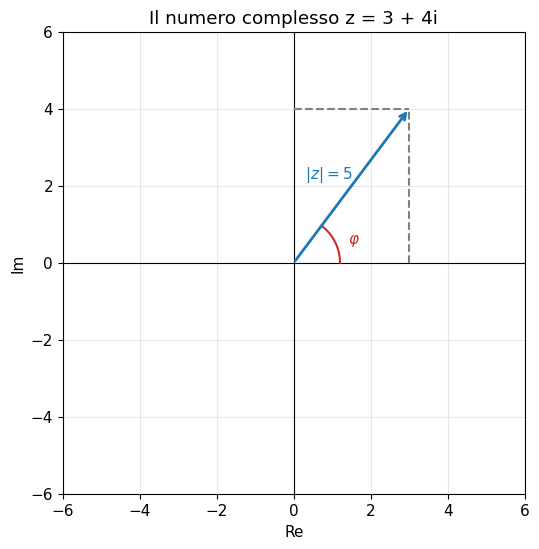

In [2]:
z = 3 + 4j
print("z           =", z)
print("Re(z)       =", z.real)
print("Im(z)       =", z.imag)
print("|z|         =", abs(z))
print("arg(z) [rad]=", cmath.phase(z))
print("arg(z) [deg]=", math.degrees(cmath.phase(z)))

fig, ax = plt.subplots()
piano(ax, 6, "Il numero complesso z = 3 + 4i")
vettore(ax, z, color="C0", lw=2)
ax.plot([z.real, z.real], [0, z.imag], "--", c="gray")
ax.plot([0, z.real], [z.imag, z.imag], "--", c="gray")
t = np.linspace(0, cmath.phase(z), 60)
ax.plot(1.2 * np.cos(t), 1.2 * np.sin(t), c="C3") # used to plot the angle in red (C3)
ax.text(1.4, 0.5, r"$\varphi$", color="C3")
ax.text(z.real / 2 - 1.2, z.imag / 2 + 0.2, r"$|z|=5$", color="C0")
plt.show()

### Somma e prodotto tra numeri complessi: relazione tra algebra e geometria
- La **somma** si fa *componente per componente*: è la regola del parallelogramma dei vettori.
- Il **prodotto** (lo vedremo in forma trigonometrica) ha un significato geometrico altrettanto interessante.

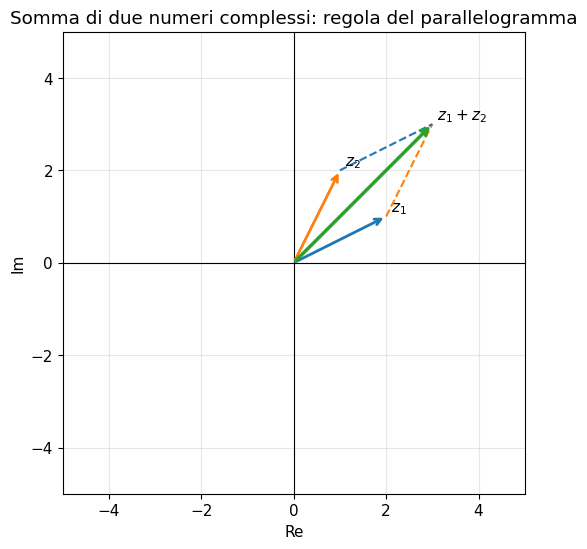

In [ ]:
z1, z2 = 2 + 1j, 1 + 2j
s = z1 + z2

fig, ax = plt.subplots()
piano(ax, 5, "Somma di due numeri complessi: regola del parallelogramma")
vettore(ax, z1, color="C0", lw=2)
vettore(ax, z2, color="C1", lw=2)
vettore(ax, s,  color="C2", lw=2.5)
ax.plot([z1.real, s.real], [z1.imag, s.imag], "--", c="C1")
ax.plot([z2.real, s.real], [z2.imag, s.imag], "--", c="C0")
for w, nome in [(z1, "$z_1$"), (z2, "$z_2$"), (s, "$z_1+z_2$")]:
    ax.text(w.real + 0.1, w.imag + 0.1, nome)
plt.show()

In [3]:
# Conversione tra forma algebrica e forma trigonometrica
def a_polare(z):
    # Restituisce (modulo, argomento) con argomento in (-pi, pi].
    return abs(z), cmath.phase(z)

def da_polare(r, phi):
    return r * (math.cos(phi) + 1j * math.sin(phi))

for z in [1 + 1j, -2, 3j, -1 - 1j]:
    r, phi = a_polare(z)
    print(f"{str(z):>10}  ->  r = {r:.4f},  phi = {phi:.4f} rad  ->  ricostruito: {da_polare(r, phi):.4f}")

    (1+1j)  ->  r = 1.4142,  phi = 0.7854 rad  ->  ricostruito: 1.0000+1.0000j
        -2  ->  r = 2.0000,  phi = 3.1416 rad  ->  ricostruito: -2.0000+0.0000j
        3j  ->  r = 3.0000,  phi = 1.5708 rad  ->  ricostruito: 0.0000+3.0000j
   (-1-1j)  ->  r = 1.4142,  phi = -2.3562 rad  ->  ricostruito: -1.0000-1.0000j


## 2. La formula di Eulero

$$\boxed{\,e^{i\theta}=\cos\theta+i\sin\theta\,}\qquad\theta\in\mathbb{R}$$

### Da dove nasce? (traccia di dimostrazione con le serie)
Ricordiamo gli sviluppi in serie di Taylor, validi per ogni $x$ reale:
$$e^{x}=\sum_{k=0}^{\infty}\frac{x^k}{k!},\qquad
\cos x=\sum_{m=0}^{\infty}\frac{(-1)^m x^{2m}}{(2m)!},\qquad
\sin x=\sum_{m=0}^{\infty}\frac{(-1)^m x^{2m+1}}{(2m+1)!}.$$

Si **definisce** $e^{i\theta}$ usando la stessa serie e le potenze di $i$
($i^0=1,\ i^1=i,\ i^2=-1,\ i^3=-i,\ i^4=1,\dots$):
$$e^{i\theta}=\underbrace{\Big(1-\frac{\theta^2}{2!}+\frac{\theta^4}{4!}-\cdots\Big)}_{\cos\theta}
+\,i\underbrace{\Big(\theta-\frac{\theta^3}{3!}+\frac{\theta^5}{5!}-\cdots\Big)}_{\sin\theta}.$$

(Il riordinamento dei termini è lecito perché la serie dell'esponenziale converge assolutamente.)

### Conseguenze immediate
- $|e^{i\theta}|=\sqrt{\cos^2\theta+\sin^2\theta}=1$: $e^{i\theta}$ si trova sulla **circonferenza unitaria**;
- $e^{i\theta}e^{i\psi}=e^{i(\theta+\psi)}$ (si conservano le proprietà delle potenze);
- **identità di Eulero:** $e^{i\pi}+1=0$ (una delle formule più belle della matematica).

### Simulazione 1 — la serie converge davvero?
Calcoliamo le somme parziali $S_N(\theta)=\sum_{k=0}^{N}\frac{(i\theta)^k}{k!}$ e confrontiamole con $\cos\theta+i\sin\theta$.

In [4]:
def exp_taylor(z, N):
    # Somma parziale N-esima della serie di e^z.
    return sum(z**k / math.factorial(k) for k in range(N + 1))

theta = 2.0
esatto = math.cos(theta) + 1j * math.sin(theta)

print(f"cos(theta) + i sin(theta) = {esatto:.12f}\n")
print(" N      S_N(i*theta)                          errore")
for N in [1, 2, 3, 5, 8, 12, 16]:
    S = exp_taylor(1j * theta, N)
    print(f"{N:2d}   {S.real:+.10f} {S.imag:+.10f}i     {abs(S - esatto):.2e}")

print("\nIdentita' di Eulero: e^(i*pi) + 1 =", np.exp(1j * np.pi) + 1)
print("(zero a meno dell'errore di arrotondamento, ~1e-16)")

cos(theta) + i sin(theta) = -0.416146836547+0.909297426826j

 N      S_N(i*theta)                          errore
 1   +1.0000000000 +2.0000000000i     1.79e+00
 2   -1.0000000000 +2.0000000000i     1.24e+00
 3   -1.0000000000 +0.6666666667i     6.32e-01
 5   -0.3333333333 +0.9333333333i     8.62e-02
 8   -0.4158730159 +0.9079365079i     1.39e-03
12   -0.4161466517 +0.9092961360i     1.30e-06
16   -0.4161468365 +0.9092974265i     3.66e-10

Identita' di Eulero: e^(i*pi) + 1 = 1.2246467991473532e-16j
(zero a meno dell'errore di arrotondamento, ~1e-16)


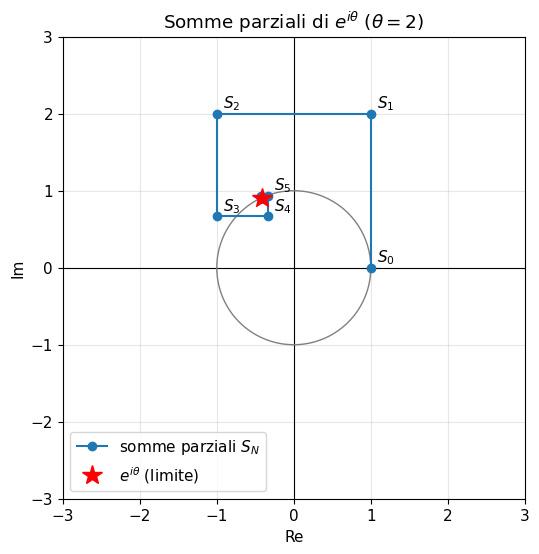

In [ ]:
# Le somme parziali "camminano" nel piano fino a raggiungere il punto sulla circonferenza unitaria
theta = 2.0
punti = np.array([exp_taylor(1j * theta, N) for N in range(0, 14)])

fig, ax = plt.subplots()
piano(ax, 3, r"Somme parziali di $e^{i\theta}$ ($\theta=2$)")
t = np.linspace(0, 2 * np.pi, 400)
ax.plot(np.cos(t), np.sin(t), c="gray", lw=1)
ax.plot(punti.real, punti.imag, "o-", c="C0", label="somme parziali $S_N$")
for N in range(0, 6):
    ax.text(punti[N].real + 0.08, punti[N].imag + 0.08, f"$S_{N}$")
ax.plot([np.cos(theta)], [np.sin(theta)], "r*", ms=15, label=r"$e^{i\theta}$ (limite)")
ax.legend(loc="lower left")
plt.show()

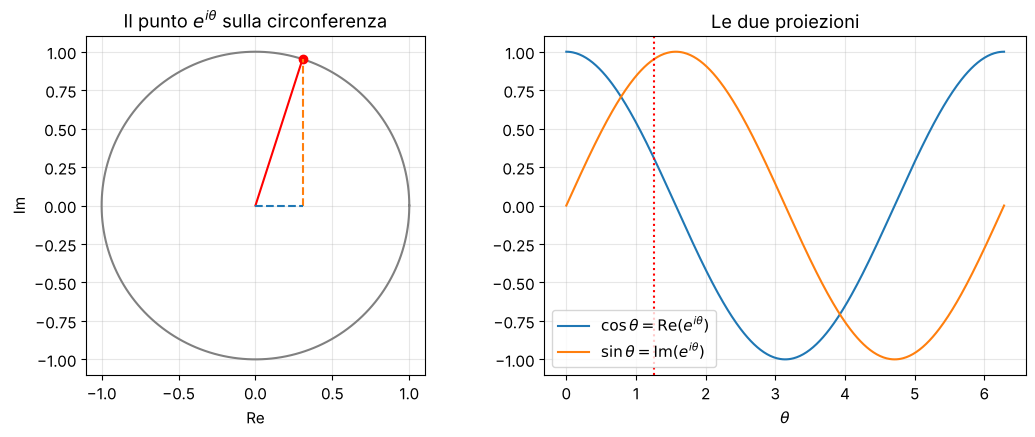

In [ ]:
# Parte reale e parte immaginaria di e^{i theta} = coseno e seno (proiezioni del punto che ruota)
th = np.linspace(0, 2 * np.pi, 400)
w = np.exp(1j * th)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.5))
a1.plot(w.real, w.imag, c="gray")
k = 80
a1.plot([w[k].real], [w[k].imag], "ro")
a1.plot([0, w[k].real], [0, w[k].imag], "r-")
a1.plot([w[k].real, w[k].real], [0, w[k].imag], "C1--")
a1.plot([0, w[k].real], [0, 0], "C0--")
a1.set_aspect("equal"); a1.set_title(r"Il punto $e^{i\theta}$ sulla circonferenza")
a1.set_xlabel("Re"); a1.set_ylabel("Im")

a2.plot(th, w.real, label=r"$\cos\theta=\mathrm{Re}(e^{i\theta})$", c="C0")
a2.plot(th, w.imag, label=r"$\sin\theta=\mathrm{Im}(e^{i\theta})$", c="C1")
a2.axvline(th[k], c="r", ls=":")
a2.set_xlabel(r"$\theta$"); a2.legend(); a2.set_title("Le due proiezioni")
plt.tight_layout(); plt.show()

## 3. Forma esponenziale, prodotto e potenze

Grazie a Eulero ogni $z\ne0$ si scrive
$$z=r\,e^{i\varphi},\qquad r=|z|>0,\ \varphi=\arg z.$$

**Prodotto:** se $z_1=r_1e^{i\varphi_1}$ e $z_2=r_2e^{i\varphi_2}$ allora
$$z_1z_2=r_1r_2\,e^{i(\varphi_1+\varphi_2)}:$$
*i moduli si moltiplicano, gli argomenti si sommano.* Moltiplicare per $z_2$ equivale a una **rotazione di $\varphi_2$ combinata con una omotetia di rapporto $r_2$**.

**Potenza (formula di De Moivre):** per $n\in\mathbb{N}$
$$z^n=r^n\,e^{in\varphi}=r^n\big(\cos n\varphi+i\sin n\varphi\big).$$
(Si dimostra per induzione su $n$ usando la regola del prodotto.)

### Simulazione 2 — verifica numerica della regola del prodotto

|z1|*|z2|        = 3.0000000000000004
|z1*z2|          = 3.0
arg z1 + arg z2  = 1.5707963267948966
arg(z1*z2)       = 1.5707963267948963


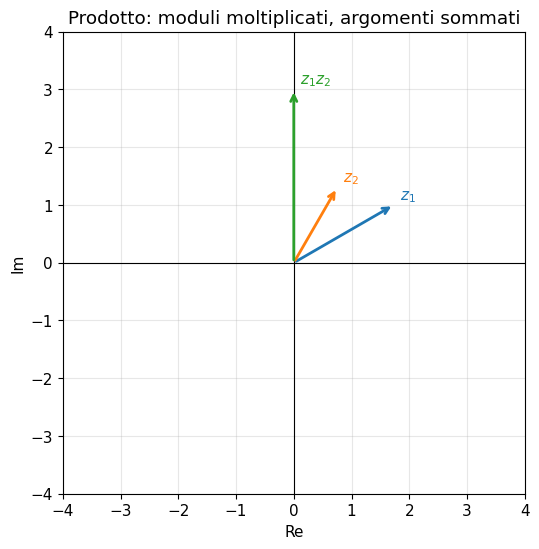

In [ ]:
z1 = 2.0 * np.exp(1j * np.pi / 6)
z2 = 1.5 * np.exp(1j * np.pi / 3)
p = z1 * z2

print("|z1|*|z2|        =", abs(z1) * abs(z2))
print("|z1*z2|          =", abs(p))
print("arg z1 + arg z2  =", np.angle(z1) + np.angle(z2))
print("arg(z1*z2)       =", np.angle(p))

fig, ax = plt.subplots()
piano(ax, 4, "Prodotto: moduli moltiplicati, argomenti sommati")
for w, c, n in [(z1, "C0", "$z_1$"), (z2, "C1", "$z_2$"), (p, "C2", "$z_1z_2$")]:
    vettore(ax, w, color=c, lw=2)
    ax.text(w.real + 0.1, w.imag + 0.1, n, color=c)
plt.show()

### Cosa succede se $|z|=1$? I poligoni regolari
Se $z=e^{i\varphi}$ le potenze $z^n=e^{in\varphi}$ ruotano sempre dello stesso angolo restando
sulla circonferenza unitaria: sono i vertici di un **poligono regolare** .

Ora la domanda interessante: **e se $|z|\neq 1$?**  Il modulo $r^n$ cresce (o decresce) a ogni passo, mentre l'angolo continua a ruotare dello stesso passo... Intuitivamente: una spirale!

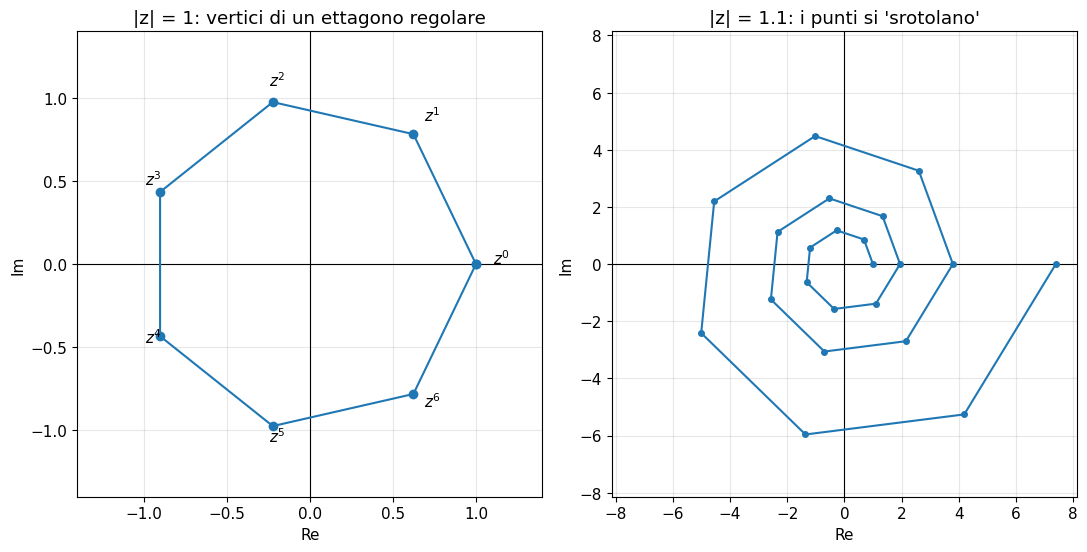

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 5.5))

# |z| = 1  ->  poligono regolare (m = 7)
m = 7
z = np.exp(2j * np.pi / m)
P = z ** np.arange(0, m + 1)
piano(axs[0], 1.4, "|z| = 1: vertici di un ettagono regolare")
axs[0].plot(P.real, P.imag, "o-")
for n in range(m):
    axs[0].text(P[n].real * 1.1, P[n].imag * 1.1, f"$z^{n}$")

# |z| = 1.1  ->  i punti si allontanano
z = 1.1 * np.exp(2j * np.pi / m)
P = z ** np.arange(0, 3 * m + 1)
piano(axs[1], 1.1 ** (3 * m) * 1.1, "|z| = 1.1: i punti si 'srotolano'")
axs[1].plot(P.real, P.imag, "o-", ms=4)
plt.tight_layout(); plt.show()

## 4. La spirale logaritmica

In coordinate polari $(\rho,\theta)$ la **spirale logaritmica** è la curva
$$\rho(\theta)=a\,e^{b\theta},\qquad a>0,\ b\in\mathbb{R}.$$


### Proprietà
1. **Equiangolarità.** Poiché $\rho'(\theta)=a \cdot b e^{b\theta}=b \cdot \rho(\theta)$, l'angolo $\alpha$ tra il raggio vettore $\rho$ e la tangente $\rho'$ è **costante** in ogni punto. Ricordiamo infatti che, in coordinate polari, $\tan(\alpha)= \frac{\rho(\theta)}{\rho'(\theta)}=\frac{1}{b}$.
2. **Autosimilarità.** $\rho(\theta+\alpha)=ae^{b(\theta +\alpha)}=\rho(\theta)e^{b\alpha}$: ruotare di $\alpha$ equivale a scalare di $e^{b\alpha}$. Ogni porzione è una copia ingrandita delle altre.
3. **Linearizzazione.** $\ln\rho=\ln a+b\theta$: nel piano $(\theta,\ln\rho)$ la spirale diventa una **retta** di pendenza $b$.
4. Se $b>0$ si allontana dall'origine al crescere di $\theta$; se $b<0$ vi si avvicina senza mai raggiungerla; se $b=0$ è una circonferenza.
5. Approssima forme naturali (conchiglie di nautilus, bracci di galassie a spirale, traiettorie di alcuni insetti verso una luce).

### Simulazione 3 — una famiglia di spirali

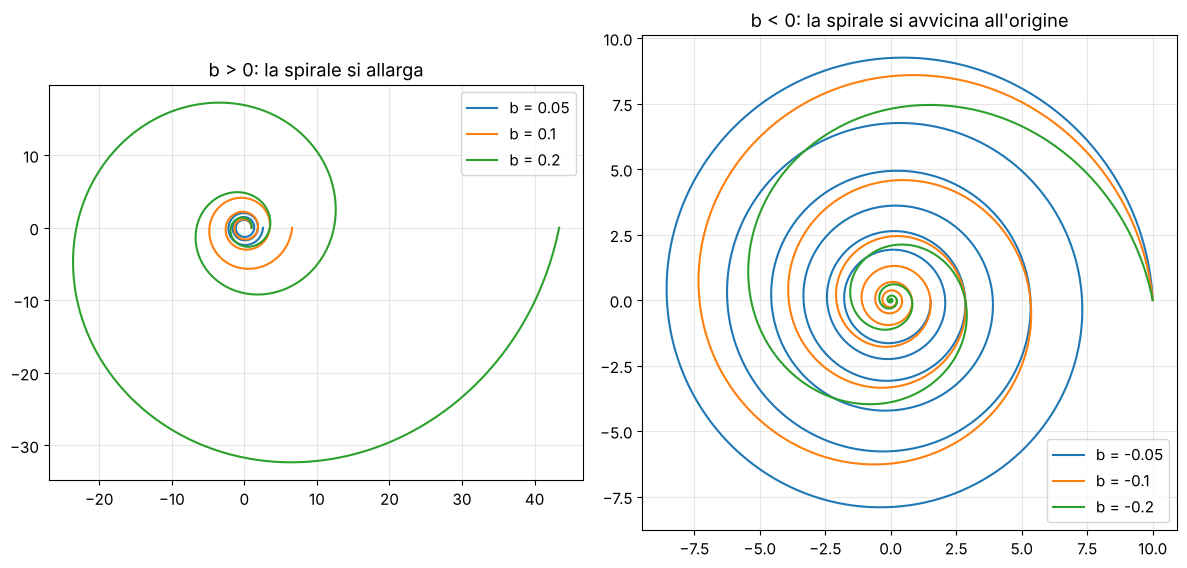

In [ ]:
def spirale(a, b, theta):
    # Spirale logaritmica a*exp((b + i) theta), in forma complessa.
    return a * np.exp((b + 1j) * theta)

theta = np.linspace(0, 6 * np.pi, 2000)

fig, axs = plt.subplots(1, 2, figsize=(12, 6))
for b in [0.05, 0.10, 0.20]:
    g = spirale(1, b, theta)
    axs[0].plot(g.real, g.imag, label=f"b = {b}")
axs[0].set_aspect("equal"); axs[0].legend(); axs[0].set_title("b > 0: la spirale si allarga")

theta2 = np.linspace(0, 12 * np.pi, 4000)
for b in [-0.05, -0.10, -0.20]:
    g = spirale(10, b, theta2)
    axs[1].plot(g.real, g.imag, label=f"b = {b}")
axs[1].set_aspect("equal"); axs[1].legend(); axs[1].set_title("b < 0: la spirale si avvicina all'origine")
plt.tight_layout(); plt.show()

In [ ]:
# Verifica numerica delle proprieta' 1 e 2
a, b = 1.0, 0.15
th = np.linspace(0, 8 * np.pi, 20001)
g = spirale(a, b, th)

# 1) angolo tra raggio vettore e tangente (tangente ~ differenza finita)
dg = np.diff(g)
medio = (g[1:] + g[:-1]) / 2
angolo = np.angle(dg / medio)               # arg(tangente / raggio)
print("Angolo tra raggio e tangente:")
print(f"  minimo  = {np.degrees(angolo.min()):.6f} gradi")
print(f"  massimo = {np.degrees(angolo.max()):.6f} gradi")
print(f"  teorico arctan(1/b) = {np.degrees(np.arctan2(1, b)):.6f} gradi")

# 2) autosimilarita': gamma(theta + alpha) = e^{(b+i) alpha} * gamma(theta)
alpha = 1.3
t0 = 2.0
lhs = spirale(a, b, t0 + alpha)
rhs = np.exp((b + 1j) * alpha) * spirale(a, b, t0)
print("\nAutosimilarita':  |lhs - rhs| =", abs(lhs - rhs))

# 3) linearizzazione: ln(rho) = ln(a) + b*theta
pendenza, intercetta = np.polyfit(th, np.log(np.abs(g)), 1)
print(f"\nRetta in (theta, ln rho): pendenza = {pendenza:.6f} (teorico b = {b}), intercetta = {intercetta:.6f} (ln a = {np.log(a):.6f})")

Angolo tra raggio e tangente:
  minimo  = 81.469232 gradi
  massimo = 81.469232 gradi
  teorico arctan(1/b) = 81.469234 gradi

Autosimilarita':  |lhs - rhs| = 5.551115123125783e-16

Retta in (theta, ln rho): pendenza = 0.150000 (teorico b = 0.15), intercetta = -0.000000 (ln a = 0.000000)


## 5. Teorema: le potenze $z^n$ stanno su una spirale logaritmica

> **Teorema.** Sia $z=r\,e^{i\varphi}$ con $r>0,\ r\ne1$ e $\varphi\in(-\pi,\pi]$, $\varphi\neq0$. Allora tutti i punti $z^n$, $n=0,1,2,\dots$, appartengono alla spirale logaritmica
> $$\rho(\theta)=ae^{b\theta}, \qquad\text{con }\ a=1 \text{ e }\ b=\frac{\ln r}{\varphi}$$


### Dimostrazione
**Passo 1 (calcolo di $z^n$).** Per la formula di De Moivre
$$z^n=r^n e^{in\varphi}.$$
Quindi le coordinate polari di $z^n$ sono $(\rho, \theta)=(r^n, n\varphi)$

**Passo 2 (i punti appartengono ad una spirale).** Dobbiamo ora mostrare i punti $z^n$ si trovano su una spirale logaritmica, ovvero trovare $a$ e $b$ tali che $\rho = a e^{b\theta} → r^n = a e^{bn\varphi}$ per ogni $n \in \mathbb{N}$. Scriviamo $\rho=r^n=e^{\ln(r^n)}=e^{n \ln(r)}$. Visto che $n = \frac{\theta}{\varphi}$, l'equazioni precedente diventa $\rho= e^{\frac{\theta}{\varphi} \ln(r)}$ e ponendo $a=1$ e $b= \frac{ln(r)}{\varphi}$ abbiamo l'equazione di una spirale logaritmica.   $\blacksquare$

**Passo 3 (lettura equivalente).** Da $\rho=r^n$ e $\theta=n\varphi$ si ricava $n=\theta\varphi$, quindi
$$\ln\rho=n\ln r=\frac{\ln r}{\varphi}\,\theta.$$
Nel piano i punti $(r^n,n\varphi)$ stanno su una **retta per l'origine di pendenza $\frac{\ln(r)}{\varphi}$**: ecco la spirale "raddrizzata".

### Osservazioni importanti
- **Interpretazione.** Ogni moltiplicazione per $z$ è una *rotazione di $\varphi$* più una *omotetia di rapporto $r$*: la stessa trasformazione applicata sempre, quindi i punti si dispongono su una curva autosimilare.
- **Se $|z|>1$** la spirale si allontana ($\theta_n$ cresce in modulo e $\rho_n$ cresce);
- **se $|z|<1$** la spirale si avvicina all'origine.
- **Se $|z|=1$** si ha $k=0$: la spirale degenera nella circonferenza unitaria.
- **Se $\varphi=0$** ($z$ reale positivo) non c'è rotazione: i punti stanno su una semiretta, non su una spirale.
- **Trappola numerica (e logica!).** L'angolo $\theta_n=n\varphi$ **non è** l'argomento principale di $z^n$: quest'ultimo è ridotto modulo $2\pi$ in $(-\pi,\pi]$. Per leggere la spirale serve l'argomento *"srotolato"* $n\varphi$. Lo vedremo con una simulazione.

### Simulazione 4 — verifica numerica del teorema

In [ ]:
def verifica_teorema(z, N=30):
    # Verifica numericamente che z^n appartiene alla spirale rho = exp(k*theta).
    r, phi = abs(z), np.angle(z)
    k = np.log(r) / phi
    n = np.arange(0, N + 1)
    P = z ** n                               # i punti z^n
    theta_n = n * phi                        # argomento "srotolato"
    gamma_n = np.exp((k + 1j) * theta_n)     # punti della spirale agli angoli theta_n
    errore_assoluto = np.abs(P - gamma_n)
    errore_relativo = errore_assoluto / np.abs(P)
    return k, P, theta_n, errore_relativo

z = 1.15 * np.exp(1j * 0.6)
k, P, theta_n, err = verifica_teorema(z, 30)

print(f"z = {z:.4f}   |z| = {abs(z):.3f}   arg z = {np.angle(z):.3f} rad")
print(f"k = ln(r)/phi = {k:.6f}")
print(f"Massimo errore relativo tra z^n e gamma(n*phi): {err.max():.2e}")
print("\n n     |z^n|        theta_n      ln|z^n| / theta_n")
for n in [1, 2, 3, 5, 10, 20, 30]:
    print(f"{n:2d}   {abs(P[n]):10.5f}   {theta_n[n]:9.4f}   {np.log(abs(P[n])) / theta_n[n]:.6f}")

z = 0.9491+0.6493j   |z| = 1.150   arg z = 0.600 rad
k = ln(r)/phi = 0.232937
Massimo errore relativo tra z^n e gamma(n*phi): 2.70e-15

 n     |z^n|        theta_n      ln|z^n| / theta_n
 1      1.15000      0.6000   0.232937
 2      1.32250      1.2000   0.232937
 3      1.52087      1.8000   0.232937
 5      2.01136      3.0000   0.232937
10      4.04556      6.0000   0.232937
20     16.36654     12.0000   0.232937
30     66.21177     18.0000   0.232937


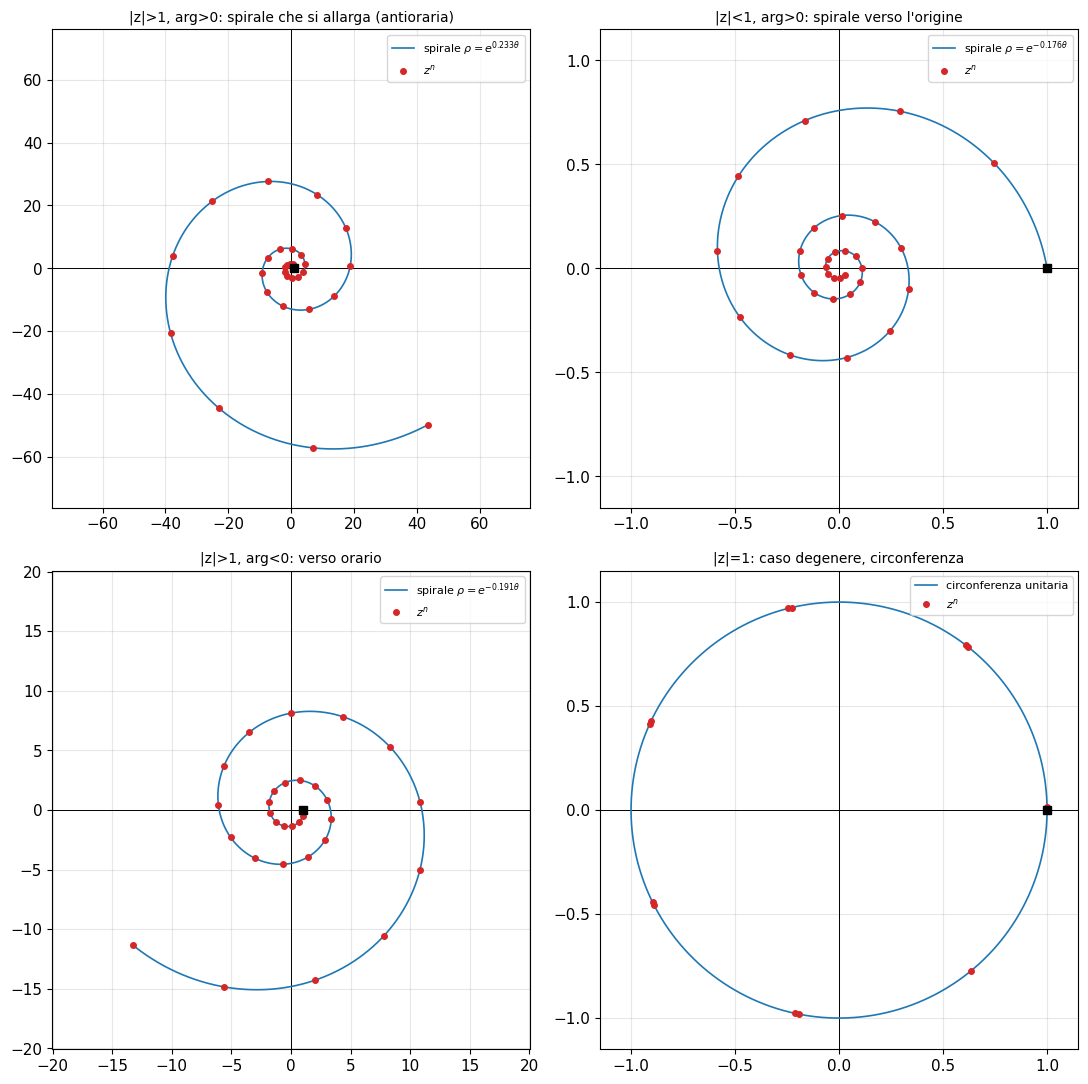

In [ ]:
def figura_potenze(ax, z, N=30, titolo=""):
    r, phi = abs(z), np.angle(z)
    n = np.arange(0, N + 1)
    P = z ** n
    lim = 1.15 * max(np.abs(P).max(), 1)
    ax.set_aspect("equal"); ax.axhline(0, c="k", lw=.7); ax.axvline(0, c="k", lw=.7)
    if abs(phi) > 1e-12 and abs(r - 1) > 1e-12:
        k = np.log(r) / phi
        th = np.linspace(0, N * phi, 4000)
        g = np.exp((k + 1j) * th)
        ax.plot(g.real, g.imag, c="C0", lw=1.2, label=fr"spirale $\rho=e^{{{k:.3f}\theta}}$")
    else:
        t = np.linspace(0, 2 * np.pi, 400)
        ax.plot(np.cos(t), np.sin(t), c="C0", lw=1.2, label="circonferenza unitaria")
    ax.plot(P.real, P.imag, "o", c="C3", ms=4, label="$z^n$")
    ax.plot([1], [0], "ks", ms=6)  # z^0 = 1
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_title(titolo, fontsize=10)
    ax.legend(loc="upper right", fontsize=8)

casi = [
    (1.15 * np.exp(1j * 0.6),  "|z|>1, arg>0: spirale che si allarga (antioraria)"),
    (0.90 * np.exp(1j * 0.6),  "|z|<1, arg>0: spirale verso l'origine"),
    (1.10 * np.exp(-1j * 0.5), "|z|>1, arg<0: verso orario"),
    (1.00 * np.exp(1j * 0.9),  "|z|=1: caso degenere, circonferenza"),
]
fig, axs = plt.subplots(2, 2, figsize=(11, 11))
for ax, (z, tit) in zip(axs.ravel(), casi):
    figura_potenze(ax, z, N=30 if abs(z) != 1 else 12, titolo=tit)
plt.tight_layout(); plt.show()

### La trappola dell'argomento principale
Se per calcolare $k$ usassimo l'argomento *principale* di $z^n$ (quello che restituisce `np.angle`) invece di $n\varphi$, il rapporto $\ln|z^n|/\theta$ **non sarebbe costante**.
Verifichiamolo e poi mostriamo la linearizzazione corretta.

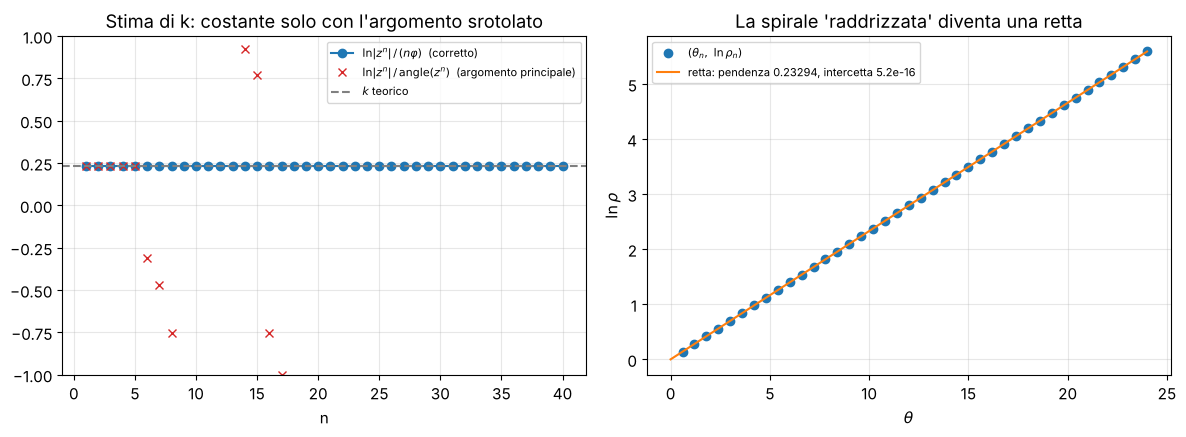

k teorico = ln(r)/phi = 0.232937,  pendenza stimata = 0.232937


In [ ]:
z = 1.15 * np.exp(1j * 0.6)
r, phi = abs(z), np.angle(z)
n = np.arange(1, 41)
P = z ** n

k_corretto = np.log(np.abs(P)) / (n * phi)       # con argomento "srotolato"
k_sbagliato = np.log(np.abs(P)) / np.angle(P)    # con argomento principale (ridotto)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].plot(n, k_corretto, "o-", label=r"$\ln|z^n|\,/\,(n\varphi)$  (corretto)")
axs[0].plot(n, k_sbagliato, "x", c="C3", label=r"$\ln|z^n|\,/\,\mathrm{angle}(z^n)$  (argomento principale)")
axs[0].axhline(np.log(r) / phi, c="gray", ls="--", label="$k$ teorico")
axs[0].set_ylim(-1, 1); axs[0].set_xlabel("n"); axs[0].legend(fontsize=8)
axs[0].set_title("Stima di k: costante solo con l'argomento srotolato")

# Linearizzazione: i punti (theta_n, ln rho_n) stanno su una retta
theta_n = n * phi
axs[1].plot(theta_n, np.log(np.abs(P)), "o", label=r"$(\theta_n,\ \ln\rho_n)$")
pend, inter = np.polyfit(theta_n, np.log(np.abs(P)), 1)
xx = np.linspace(0, theta_n.max(), 10)
axs[1].plot(xx, pend * xx + inter, "-", label=f"retta: pendenza {pend:.5f}, intercetta {inter:.1e}")
axs[1].set_xlabel(r"$\theta$"); axs[1].set_ylabel(r"$\ln\rho$"); axs[1].legend(fontsize=8)
axs[1].set_title("La spirale 'raddrizzata' diventa una retta")
plt.tight_layout(); plt.show()

print(f"k teorico = ln(r)/phi = {np.log(r) / phi:.6f},  pendenza stimata = {pend:.6f}")

### Simulazione 5 — animazione: la spirale prende forma
A ogni fotogramma si aggiunge una nuova potenza: ciascun punto nasce dal precedente applicando *la stessa* rotazione + omotetia.

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

matplotlib.rcParams["animation.embed_limit"] = 60   # MB

def animazione_potenze(z, N=40, intervallo=150):
    r, phi = abs(z), np.angle(z)
    k = np.log(r) / phi
    P = z ** np.arange(0, N + 1)
    lim = 1.15 * max(np.abs(P).max(), 1)
    th = np.linspace(0, N * phi, 3000)
    g = np.exp((k + 1j) * th)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_aspect("equal"); ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.axhline(0, c="k", lw=.7); ax.axvline(0, c="k", lw=.7)
    ax.set_title(fr"$z=${z:.2f}: potenze $z^n$ e spirale $\rho=e^{{{k:.3f}\theta}}$")
    linea, = ax.plot([], [], c="C0", lw=1)
    punti, = ax.plot([], [], "o", c="C3", ms=5)
    ultimo, = ax.plot([], [], "o", c="gold", mec="k", ms=9)
    testo = ax.text(0.03, 0.95, "", transform=ax.transAxes, va="top")

    def aggiorna(f):
        # curva fino all'angolo corrente
        m = max(2, int(len(th) * (f + 1) / (N + 1)))
        linea.set_data(g.real[:m], g.imag[:m])
        punti.set_data(P.real[:f + 1], P.imag[:f + 1])
        ultimo.set_data([P[f].real], [P[f].imag])
        testo.set_text(f"n = {f},  |z^n| = {abs(P[f]):.3f},  n*phi = {f * phi:.2f} rad")
        return linea, punti, ultimo, testo

    anim = FuncAnimation(fig, aggiorna, frames=N + 1, interval=intervallo, blit=False)
    plt.close(fig)
    return anim

anim = animazione_potenze(1.12 * np.exp(1j * 0.55), N=40)
HTML(anim.to_jshtml())

## 6. Esperimenti interattivi

Il widget seguente permette di **cambiare $r$ e $\varphi$** e osservare in tempo reale come cambia la spirale e il valore di $k=\ln r/\varphi$.
Se `ipywidgets` non fosse installato, la cella mostra comunque una figura statica.

In [ ]:
def esplora(r=1.1, phi_gradi=30.0, N=40):
    phi = math.radians(phi_gradi)
    z = r * np.exp(1j * phi)
    fig, ax = plt.subplots(figsize=(6, 6))
    if abs(phi) < 1e-9:
        ax.text(0.5, 0.5, "phi = 0: nessuna rotazione,\ni punti stanno su una semiretta",
                ha="center", transform=ax.transAxes)
    else:
        figura_potenze(ax, z, N=int(N), titolo=f"r = {r:.2f}, phi = {phi_gradi:.0f} gradi")
    plt.show()
    if abs(phi) > 1e-9:
        print(f"k = ln(r)/phi = {math.log(r) / phi:.4f}")

try:
    import ipywidgets as widgets
    widgets.interact(
        esplora,
        r=widgets.FloatSlider(min=0.5, max=1.5, step=0.01, value=1.1, description="r"),
        phi_gradi=widgets.FloatSlider(min=-180, max=180, step=1, value=30, description="phi [gradi]"),
        N=widgets.IntSlider(min=5, max=80, step=1, value=40, description="N"),
    )
except ImportError:
    print("ipywidgets non disponibile: mostro un esempio statico.")
    esplora(1.1, 30, 40)

interactive(children=(FloatSlider(value=1.1, description='r', max=1.5, min=0.5, step=0.01), FloatSlider(value=…

## 7. Esercizi, sfide e spunti di verifica

### Matematica
1. Scrivi in forma esponenziale $z=1+i\sqrt3$ e calcola $z^{6}$ a mano. Verifica con Python.
2. Dimostra per induzione la formula di De Moivre $(\cos\varphi+i\sin\varphi)^n=\cos n\varphi+i\sin n\varphi$.
3. Ricava le formule di addizione di $\sin(\alpha+\beta)$ e $\cos(\alpha+\beta)$ da $e^{i(\alpha+\beta)}=e^{i\alpha}e^{i\beta}$.
4. Per $z=0{,}9\,e^{i\pi/5}$ calcola $k$ e scrivi l'equazione polare della spirale su cui giacciono le potenze di $z$.
5. Dimostra che, per $z=re^{i\varphi}$ con $r\ne 1$, il punto $z^{n+1}$ si ottiene da $z^{n}$ con una rotazione di $\varphi$ e una omotetia di rapporto $r$ **centrate nell'origine**.
6. **Sfida.** Dimostra che anche i punti $w\,z^n$ (con $w\in\mathbb{C}\setminus\{0\}$ fissato) stanno su una spirale logaritmica. *Suggerimento:* la spirale è quella di $z^n$ ruotata di $\arg w$ e scalata di $|w|$.
7. **Sfida.** Perché per $\varphi=2\pi p/q$ ($p/q$ razionale) le potenze si dispongono su $q$ semirette uscenti dall'origine? E per $\varphi/\pi$ irrazionale?

### Informatica
1. Scrivi una funzione `potenze_su_spirale(z, N)` che restituisca gli array `(P, k, errore_massimo)`.
2. Con `time.perf_counter()` confronta il calcolo di $z^n$ con un ciclo che moltiplica ripetutamente per $z$ e con la funzione `z**n` di NumPy. Cosa osservi per $n$ grande? Prova con $|z|=1{,}001$ e $n=10^5$: ci sono *overflow* o perdita di precisione?
3. Modifica `animazione_potenze` per mostrare anche la retta di linearizzazione $(\theta,\ln\rho)$ in un secondo grafico accanto.
4. Scrivi un test automatico (ad esempio con `assert` o `pytest`) che verifichi il teorema per 100 numeri $z$ casuali con $|z|\in(0{,}5;\,2)$ e $\varphi\in(-\pi,\pi]\setminus\{0\}$.
5. **Sfida.** Disegna la *spirale di Fibonacci/spirale aurea* come spirale logaritmica con $b=\frac{2\ln\varphi_{\text{aureo}}}{\pi}$ e confrontala con l'approssimazione fatta da quarti di circonferenza.

### Spunti di verifica e valutazione
| Competenza | Indicatore | Livello atteso |
|---|---|---|
| Rappresentare numeri complessi | passa da forma algebrica a polare/esponenziale e rappresenta nel piano | autonomo |
| Argomentare | riproduce la dimostrazione del teorema spiegando il ruolo di $n\varphi$ | con motivazione |
| Modellizzare al computer | traduce la dimostrazione in verifica numerica e interpreta gli errori | con commento critico |
| Comunicare | relazione breve con grafici, formule e conclusioni | chiara e corretta |

### Spunti di approfondimento
- Funzione esponenziale complessa $e^{z}=e^{x}(\cos y+i\sin y)$ e logaritmo complesso (multivalore).
- Trasformazioni del piano: rotazioni, omotetie e similitudini come moltiplicazioni per un numero complesso.
- Radici $n$-esime di un numero complesso e frattali (insieme di Mandelbrot / Julia: iterazioni di $z\mapsto z^2+c$).
- Spirali in natura, arte e architettura.